In [3]:

import os
import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Total storage: {total / (1024**3):.2f} GB")
print(f"Used storage: {used / (1024**3):.2f} GB")
print(f"Free storage: {free / (1024**3):.2f} GB")



Total storage: 112.64 GB
Used storage: 0.16 GB
Free storage: 112.46 GB


In [4]:

import os

DATASET_DIR = "/content/drive/MyDrive/AgriFreshNET Freshness and Shelf-Life Image Datase"

print("Dataset exists:", os.path.exists(DATASET_DIR))

folders = [
    f for f in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, f))
]

print("Number of folders:", len(folders))
print("Folder names:")

for folder in sorted(folders):
    print(folder)



Dataset exists: True
Number of folders: 24
Folder names:
Fresh Banana(1-4)
Fresh Bittermelon(1-3)
Fresh Cucumber(1-6)
Fresh Orange(1-9)
Fresh Papaya(1-4)
Fresh Tomato(1-10)
Fresh eggplant(1-4)
Fresh pineapple(1-15)
Rotten Bittermelon(5-8)
Rotten Cucumber(12-20)
Rotten Orange(20-35)
Rotten Papaya(7-12)
Rotten Pineapple(25-35)
Rotten Tomato(24-35)
Rotten banana(7-13)
Rotten eggplant(8-15)
Semi Fresh Bittermelon ( 3-5)
Semi Fresh Cucumber(6-12)
Semi Fresh Papaya(4-7)
Semi fresh Orange(9-20)
Semi fresh Pineapple (15-25)
Semi fresh Tomato(10-24)
Semi fresh banana(4-7)
Semi_Fresh eggplant(4-8)


In [6]:

import pandas as pd
import os

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

folder_records = []

for folder in sorted(os.listdir(DATASET_DIR)):

    folder_path = os.path.join(DATASET_DIR, folder)

    if not os.path.isdir(folder_path):
        continue

    image_count = 0

    for root, dirs, files_list in os.walk(folder_path):

        image_count += sum(
            1 for file in files_list
            if file.lower().endswith(IMAGE_EXTENSIONS)
        )

    name = folder.lower().replace("_", " ").replace("-", " ")

    if name.startswith("semi"):
        freshness = "Semi-Fresh"
    elif name.startswith("rotten"):
        freshness = "Rotten"
    elif name.startswith("fresh"):
        freshness = "Fresh"
    else:
        freshness = "Unknown"

    folder_records.append({
        "Folder": folder,
        "Freshness": freshness,
        "Image Count": image_count
    })


folder_df = pd.DataFrame(folder_records)

print("Total folders:", len(folder_df))
print("Total images:", folder_df["Image Count"].sum())

display(folder_df)


Total folders: 24
Total images: 14164


,Folder,Freshness,Image Count
0,Fresh Banana(1-4),Fresh,590
1,Fresh Bittermelon(1-3),Fresh,590
2,Fresh Cucumber(1-6),Fresh,590
3,Fresh Orange(1-9),Fresh,590
4,Fresh Papaya(1-4),Fresh,590
5,Fresh Tomato(1-10),Fresh,590
6,Fresh eggplant(1-4),Fresh,590
7,Fresh pineapple(1-15),Fresh,590
8,Rotten Bittermelon(5-8),Rotten,590
9,Rotten Cucumber(12-20),Rotten,590


Class distribution:


,Freshness,Image Count
0,Fresh,4720
1,Semi-Fresh,4720
2,Rotten,4724



Class percentages:


,Image Count
Freshness,
Fresh,33.32
Semi-Fresh,33.32
Rotten,33.35


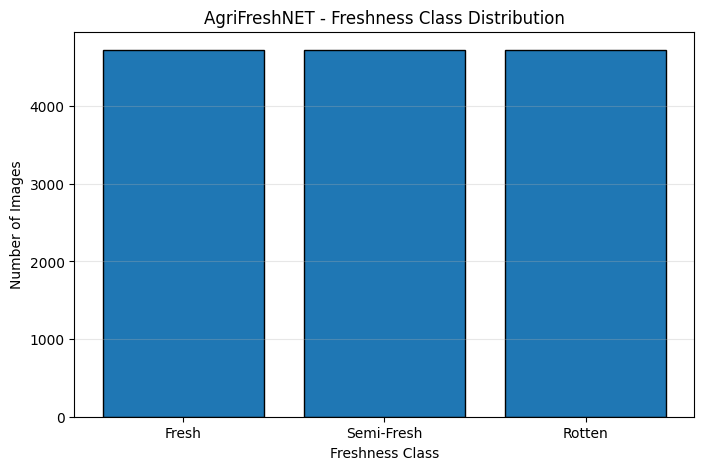

In [7]:

import matplotlib.pyplot as plt

class_counts = (
    folder_df.groupby("Freshness")["Image Count"]
    .sum()
    .reindex(["Fresh", "Semi-Fresh", "Rotten"], fill_value=0)
)

print("Class distribution:")
display(class_counts.reset_index())

print("\nClass percentages:")
display(
    (class_counts / class_counts.sum() * 100).round(2)
)

plt.figure(figsize=(8, 5))

plt.bar(
    class_counts.index,
    class_counts.values,
    edgecolor="black"
)

plt.title("AgriFreshNET - Freshness Class Distribution")
plt.xlabel("Freshness Class")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)
plt.show()


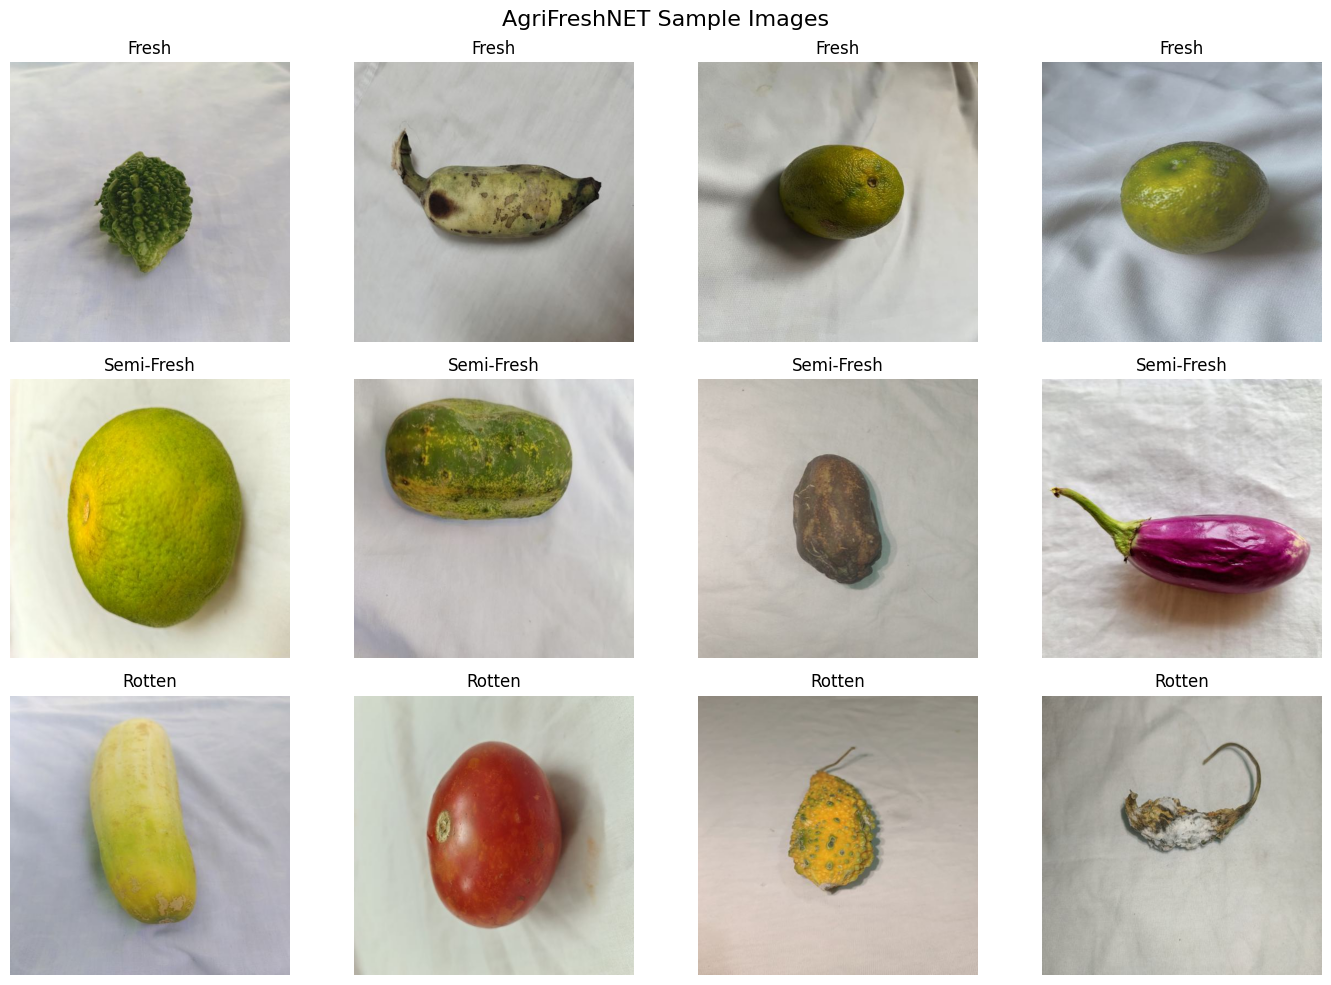

In [8]:

import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

classes = ["Fresh", "Semi-Fresh", "Rotten"]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for row, freshness in enumerate(classes):

    class_folders = folder_df[
        folder_df["Freshness"] == freshness
    ]["Folder"].tolist()

    class_images = []

    for folder in class_folders:

        folder_path = os.path.join(DATASET_DIR, folder)

        for root, dirs, files_list in os.walk(folder_path):

            for file in files_list:

                if file.lower().endswith(IMAGE_EXTENSIONS):
                    class_images.append(
                        os.path.join(root, file)
                    )

    samples = random.sample(
        class_images,
        min(4, len(class_images))
    )

    for col in range(4):

        axes[row, col].axis("off")

        if col < len(samples):

            img = Image.open(samples[col]).convert("RGB")

            axes[row, col].imshow(img)
            axes[row, col].set_title(freshness)

plt.suptitle("AgriFreshNET Sample Images", fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:

from PIL import Image
import os
import pandas as pd

image_records = []
corrupted_images = []

for folder in sorted(os.listdir(DATASET_DIR)):

    folder_path = os.path.join(DATASET_DIR, folder)

    if not os.path.isdir(folder_path):
        continue

    for root, dirs, files_list in os.walk(folder_path):

        for file in files_list:

            if not file.lower().endswith(IMAGE_EXTENSIONS):
                continue

            image_path = os.path.join(root, file)

            try:
                with Image.open(image_path) as img:
                    img.load()

                    image_records.append({
                        "Folder": folder,
                        "Width": img.width,
                        "Height": img.height,
                        "Format": img.format
                    })

            except Exception as e:
                corrupted_images.append(image_path)

image_df = pd.DataFrame(image_records)

print("Valid images:", len(image_df))
print("Corrupted images:", len(corrupted_images))

print("\nAverage dimensions:")
print("Width:", round(image_df["Width"].mean(), 2))
print("Height:", round(image_df["Height"].mean(), 2))

print("\nImage formats:")
print(image_df["Format"].value_counts())

print("\nMost common dimensions:")
display(
    image_df.groupby(["Width", "Height"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .head(10)
)


Valid images: 14160
Corrupted images: 0

Average dimensions:
Width: 512.0
Height: 512.0

Image formats:
Format
JPEG    14160
Name: count, dtype: int64

Most common dimensions:


,Width,Height,Count
0,512,512,14160
